# 基本设置
- 依赖导入
- 数据获取
- 数据基本信息研究

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# pandas展示设置
pd.options.display.max_rows = 10 # 显示的最大行数
pd.options.display.float_format = "{:.1f}".format # 浮点数显示格式: 保留1位小数

In [28]:
# 下载数据集
rice_dataset_raw = pd.read_csv("https://download.mlcc.google.com/mledu-datasets/Rice_Cammeo_Osmancik.csv")

In [29]:
# 水稻籽粒的形态特征数据
# Area: 面积
# Perimeter: 周长
# Major_Axis_Length: 主轴长度
# Minor_Axis_Length: 次轴长度
# Eccentricity: 离心率
# Convex_Area: 凸包面积
# Extent: 范围
# Class: 水稻品种类别（Cammeo 或 Osmancik）
rice_dataset = rice_dataset_raw[[
    'Area',
    'Perimeter',
    'Major_Axis_Length',
    'Minor_Axis_Length',
    'Eccentricity',
    'Convex_Area',
    'Extent',
    'Class',
]]

rice_dataset.describe()

,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent
count,3810.0,3810.0,3810.0,3810.0,3810.0,3810.0,3810.0
mean,12667.7,454.2,188.8,86.3,0.9,12952.5,0.7
std,1732.4,35.6,17.4,5.7,0.0,1777.0,0.1
min,7551.0,359.1,145.3,59.5,0.8,7723.0,0.5
25%,11370.5,426.1,174.4,82.7,0.9,11626.2,0.6
50%,12421.5,448.9,185.8,86.4,0.9,12706.5,0.6
75%,13950.0,483.7,203.6,90.1,0.9,14284.0,0.7
max,18913.0,548.4,239.0,107.5,0.9,19099.0,0.9


# 数据预处理
- 字符串列映射为数值列
- 使用 Z-score 归一化

In [30]:
# Normalize
# 使用 Z-score 标准化方法对特征进行归一化
# Z-score: (x - mean) / std, 即该值距离平均值相差多少个标准差

# 计算数值特征的均值和标准差
feature_mean = rice_dataset.mean(numeric_only=True)
feature_std = rice_dataset.std(numeric_only=True)
# 选择数值列(除了 'Class' 列)
numerical_features = rice_dataset.select_dtypes('number').columns
# 对数值特征进行归一化
normalized_dataset = (rice_dataset[numerical_features] - feature_mean) / feature_std
# 补上 Class 列
normalized_dataset['Class'] = rice_dataset['Class']
# 将 Class 列转换为布尔值：Cammeo 为 1，Osmancik 为 0
normalized_dataset['Class_Bool'] = (
    normalized_dataset['Class'] == 'Cammeo'
).astype(int)

normalized_dataset.head()

,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent,Class,Class_Bool
0,1.5,2.0,2.3,-0.2,2.0,1.5,-1.2,Cammeo,1
1,1.1,1.1,1.0,0.9,0.4,1.2,-0.6,Cammeo,1
2,1.1,1.3,1.5,0.3,1.2,1.1,0.4,Cammeo,1
3,0.3,0.1,0.3,0.2,0.2,0.2,-0.3,Cammeo,1
4,1.2,1.5,1.3,0.5,1.0,1.3,-0.2,Cammeo,1


# 相关性分析
使用相关系数矩阵和散点图矩阵来分析特征之间的相关性

有了数据, 需要做相关性分析, 判断哪些特征对分类有帮助, 哪些特征没有帮助, 甚至可能有害.

如果图中不同颜色(不同分类)的点分布在一起, 说明这个特征对分类没有帮助. 如果图中不同颜色(不同分类)的点分布在不同区域, 说明这个特征对分类有帮助.

In [31]:
# 相关矩阵
normalized_dataset.corr(numeric_only=True)

,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent,Class_Bool
Area,1.0,1.0,0.9,0.8,0.4,1.0,-0.1,0.7
Perimeter,1.0,1.0,1.0,0.6,0.5,1.0,-0.1,0.8
Major_Axis_Length,0.9,1.0,1.0,0.5,0.7,0.9,-0.1,0.8
Minor_Axis_Length,0.8,0.6,0.5,1.0,-0.3,0.8,0.1,0.4
Eccentricity,0.4,0.5,0.7,-0.3,1.0,0.4,-0.2,0.6
Convex_Area,1.0,1.0,0.9,0.8,0.4,1.0,-0.1,0.8
Extent,-0.1,-0.1,-0.1,0.1,-0.2,-0.1,1.0,-0.1
Class_Bool,0.7,0.8,0.8,0.4,0.6,0.8,-0.1,1.0


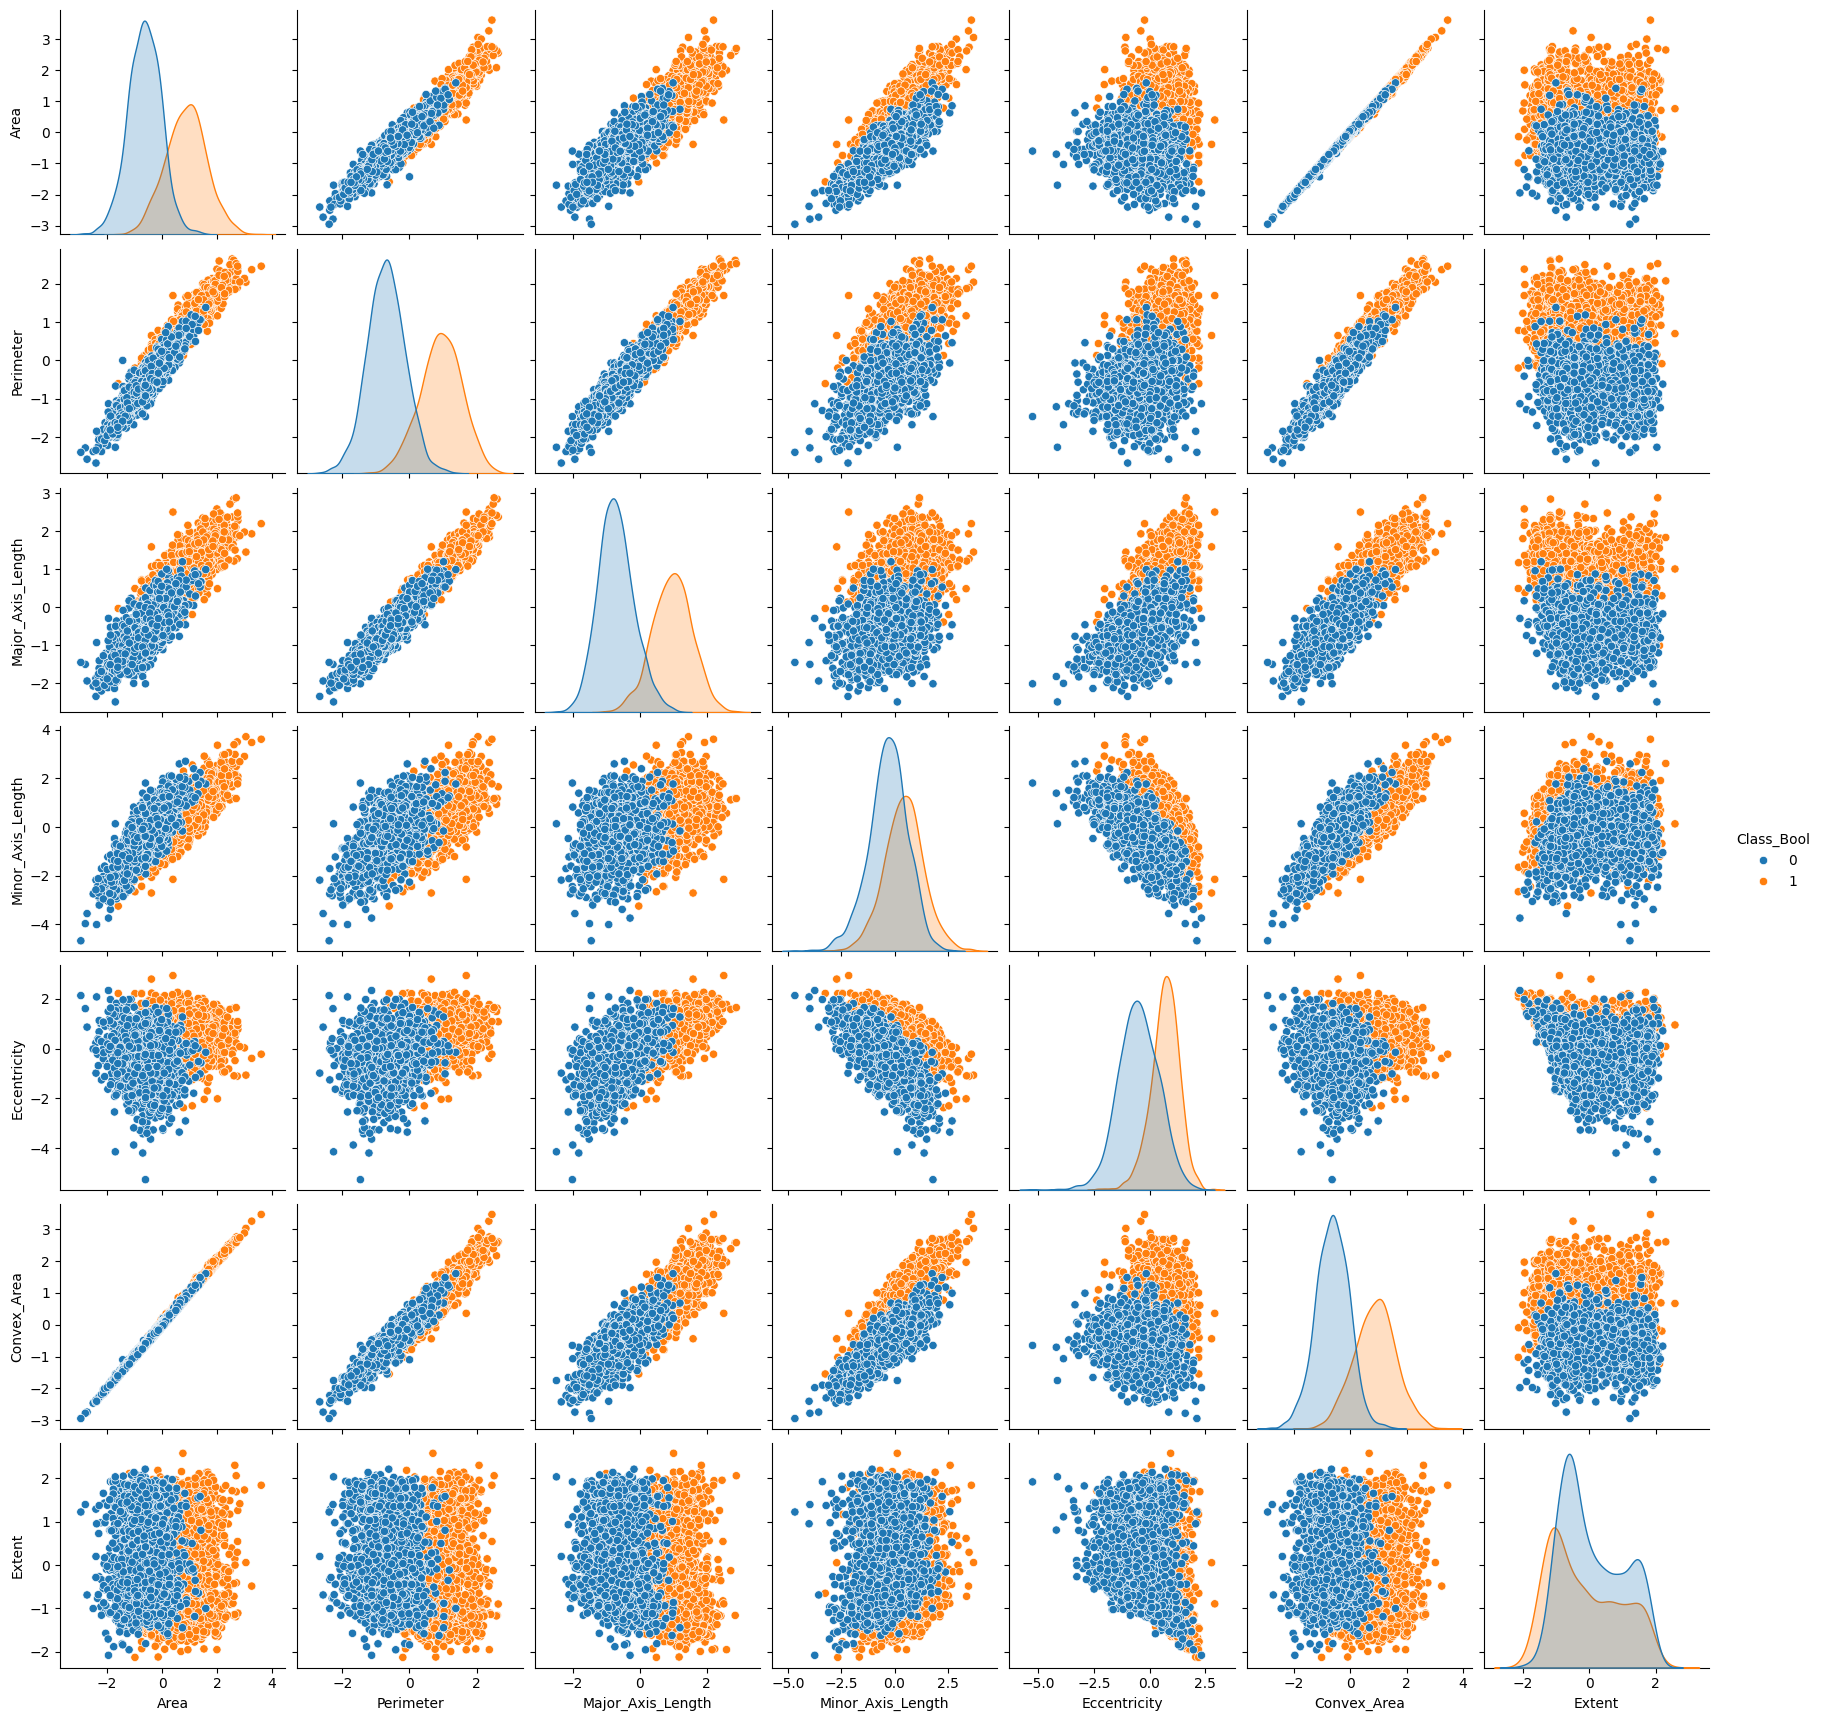

In [32]:
# 相关矩阵散点图
import seaborn as sns

sns.pairplot(data=normalized_dataset, vars=["Area", "Perimeter", "Major_Axis_Length", "Minor_Axis_Length", "Eccentricity", "Convex_Area", "Extent"], hue="Class_Bool")

In [33]:
# 根据结果, 发现extent这个特征对分类没有帮助, 因为不同类别的点在这个特征上分布在一起. 
# 其他特征对分类有帮助, 因为不同类别的点在这些特征上分布在不同区域.
# 因此, 丢弃extent这个特征, 只保留其他特征进行分类.
normalized_dataset = normalized_dataset.drop(columns=["Extent"])

In [34]:
import keras
# 设置随机数种子, 确保每次实验时可复现相同结果
keras.utils.set_random_seed(42)

In [35]:
# 划分数据集为训练集、验证集和测试集
# 样本总数
number_samples = len(normalized_dataset)
# 计算索引位置，按照 80% 训练集，10% 验证集，10% 测试集的比例划分
# 80% 的索引位置
index_80th = round(number_samples * 0.8)
# 90% 的索引位置
index_90th = index_80th + round(number_samples * 0.1)

# 打乱数据集顺序, frac=1 表示返回所有数据, random_state=100 确保每次运行时打乱的顺序相同
shuffled_dataset = normalized_dataset.sample(frac=1, random_state=100)
# 训练集, 验证集,和测试集
train_data = shuffled_dataset.iloc[0:index_80th]
validation_data = shuffled_dataset.iloc[index_80th:index_90th]
test_data = shuffled_dataset.iloc[index_90th:]

test_data.head()

,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Class,Class_Bool
2405,-0.4,-0.7,-0.8,0.3,-1.1,-0.4,Osmancik,0
3062,-0.2,-0.0,0.2,-0.7,0.8,-0.2,Osmancik,0
1155,1.4,1.2,1.1,1.2,0.3,1.3,Cammeo,1
660,1.2,1.0,0.8,1.3,-0.0,1.2,Cammeo,1
2451,-1.2,-1.2,-1.4,-0.3,-1.5,-1.1,Osmancik,0


In [36]:
# 将特征和标签分开
label_columns = ['Class', 'Class_Bool']

train_features = train_data.drop(columns=label_columns)
train_labels = train_data['Class_Bool'].to_numpy()

validation_features = validation_data.drop(columns=label_columns)
validation_labels = validation_data['Class_Bool'].to_numpy()

test_features = test_data.drop(columns=label_columns)
test_labels = test_data['Class_Bool'].to_numpy()

# 训练模型的方法定义

In [37]:
# 定义分类模型
class ClassificationModel:
    """ 
        成员变量定义与初始化
    """
    def __init__(self, learning_rate=0.001, batch_size=50, epoch = 20, threshold=0.5):
        # Linear部分
        self.coefficients = None # 系数(权重)
        self.intercept = None    # 截距(偏差)
        # 分类部分
        self.threshold = threshold # 分类阈值
        # 超参数
        self.learning_rate = learning_rate
        self.batch_size = batch_size
        self.epoch = epoch
        # 训练集指标记录
        self.loss_history = []
        self.accuracy_history = []
        self.precision_history = []
        self.recall_history = []
        # 验证集指标记录
        self.val_accuracy_history = []
        self.val_precision_history = []
        self.val_recall_history = []
    
    """
        模型公式定义所含的函数
    """
    def sigmoid(self, z):
        # Sigmoid函数, 将线性输出转换为概率值
        return 1 / (1 + np.exp(-z))
    
    def linear(self, x):
        # 线性函数, 计算线性输出
        return np.dot(x, self.coefficients) + self.intercept

    """
        训练过程中需要用到的指标函数
    """
    def logLoss(self, y_true, y_pred):
        # 计算Log Loss
        epsilon = 1e-15 # 防止log(0)的情况
        y_pred = np.clip(y_pred, epsilon, 1 - epsilon) # 将预测概率限制在 [epsilon, 1-epsilon] 范围内
        loss = -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))
        return loss
    
    def accuracy(self, y_true, y_pred):
        # 计算准确率
        return np.mean(y_true == y_pred)
    
    def precision(self, y_true, y_pred):
        # 计算精确率
        true_positive = np.sum((y_true == 1) & (y_pred == 1))
        predicted_positive = np.sum(y_pred == 1)
        if predicted_positive == 0:
            return 0.0
        return true_positive / predicted_positive
    
    def tpr(self, y_true, y_pred):
        # 计算真正例率(recall)
        true_positive = np.sum((y_true == 1) & (y_pred == 1))
        actual_positive = np.sum(y_true == 1)
        if actual_positive == 0:
            return 0.0
        return true_positive / actual_positive
    
    def fpr(self, y_true, y_pred):
        # 计算假阳性率
        false_positive = np.sum((y_true == 0) & (y_pred == 1))
        actual_negative = np.sum(y_true == 0)
        if actual_negative == 0:
            return 0.0
        return false_positive / actual_negative
    
    def confusion_matrix(self, y_true, y_pred):
        # 计算混淆矩阵
        true_positive = np.sum((y_true == 1) & (y_pred == 1))
        true_negative = np.sum((y_true == 0) & (y_pred == 0))
        false_positive = np.sum((y_true == 0) & (y_pred == 1))
        false_negative = np.sum((y_true == 1) & (y_pred == 0))
        return np.array([[true_positive, false_positive], [false_negative, true_negative]])
    
    """
        内部: 记录一个epoch的accuracy/precision/recall
    """
    def _record_metrics(self, X, y, acc_list, prec_list, rec_list):
        y_prob = self.predict_proba(X)
        y_pred = (y_prob >= self.threshold).astype(int)
        acc_list.append(self.accuracy(y, y_pred))
        prec_list.append(self.precision(y, y_pred))
        rec_list.append(self.tpr(y, y_pred))
    
    """
        模型训练
    """
    def fit(self, X, y, X_val=None, y_val=None):
        # 训练模型
        num_samples, num_features = X.shape
        # 初始化系数和截距
        self.coefficients = np.zeros(num_features)
        self.intercept = 0
        
        for epoch in range(self.epoch):
            # 打乱数据顺序
            indices = np.arange(num_samples)
            np.random.shuffle(indices)
            X_shuffled = X[indices]
            y_shuffled = y[indices]
            
            # 梯度下降更新参数
            for start in range(0, num_samples, self.batch_size):
                end = start + self.batch_size
                X_batch = X_shuffled[start:end]
                y_batch = y_shuffled[start:end]
                
                # 线性输出
                linear_output = self.linear(X_batch)
                # Sigmoid转换为概率
                y_predicted = self.sigmoid(linear_output)
                
                # 计算梯度
                error = y_predicted - y_batch
                d_coefficients = np.dot(X_batch.T, error) / len(X_batch)
                d_intercept = np.mean(error)
                
                # 更新参数
                self.coefficients -= self.learning_rate * d_coefficients
                self.intercept -= self.learning_rate * d_intercept
            
            # 每个epoch结束后: 记录训练集指标
            y_prob_train = self.predict_proba(X)
            self.loss_history.append(self.logLoss(y, y_prob_train))
            self._record_metrics(X, y, self.accuracy_history,
                                 self.precision_history, self.recall_history)
            # 记录验证集指标
            if X_val is not None and y_val is not None:
                self._record_metrics(X_val, y_val,
                                     self.val_accuracy_history,
                                     self.val_precision_history,
                                     self.val_recall_history)

    """
        预测与评估
    """
    def predict(self, X):
        # 预测函数
        linear_output = self.linear(X)
        y_predicted_prob = self.sigmoid(linear_output)
        y_predicted_class = (y_predicted_prob >= self.threshold).astype(int)
        return y_predicted_class
    
    def predict_proba(self, X):
        # 预测概率函数
        linear_output = self.linear(X)
        y_predicted_prob = self.sigmoid(linear_output)
        return y_predicted_prob
    
    def evaluate(self, X, y):
        # 评估模型性能
        y_predicted = self.predict(X)
        accuracy = self.accuracy(y, y_predicted)
        precision = self.precision(y, y_predicted)
        recall = self.tpr(y, y_predicted)
        fpr = self.fpr(y, y_predicted)
        confusion_matrix = self.confusion_matrix(y, y_predicted)
        return {
            "accuracy": accuracy,
            "precision": precision,
            "recall": recall,
            "fpr": fpr,
            "confusion_matrix": confusion_matrix
        }
    
    def plot_loss(self):
        # 绘制Loss曲线
        plt.plot(self.loss_history, label="Train Loss")
        plt.title("Loss Curve")
        plt.xlabel("Epoch")
        plt.ylabel("Log Loss")
        plt.legend()
        plt.show()
        
    def plot_indicators(self):
        # 绘制ACC, precision, recall（验证集）
        if self.val_accuracy_history:
            plt.plot(self.val_accuracy_history, label="Val Accuracy")
            plt.plot(self.val_precision_history, label="Val Precision")
            plt.plot(self.val_recall_history, label="Val Recall")
        else:
            plt.plot(self.accuracy_history, label="Accuracy")
            plt.plot(self.precision_history, label="Precision")
            plt.plot(self.recall_history, label="Recall")
        plt.title("Indicators Curve")
        plt.xlabel("Epoch")
        plt.ylabel("Value")
        plt.legend()
        plt.show()
        
    def plot_roc_curve(self, X, y):
        # 绘制ROC曲线和计算AUC
        y_predicted_prob = self.predict_proba(X)
        thresholds = np.linspace(0, 1, 100)
        tprs = []
        fprs = []
        for threshold in thresholds:
            y_predicted_class = (y_predicted_prob >= threshold).astype(int)
            tprs.append(self.tpr(y, y_predicted_class))
            fprs.append(self.fpr(y, y_predicted_class))
        plt.plot(fprs, tprs, label="ROC Curve")
        plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")
        plt.title("ROC Curve")
        plt.xlabel("False Positive Rate")
        plt.ylabel("True Positive Rate")
        plt.legend()
        plt.show()
        # 计算AUC: 按FPR升序排列确保积分方向正确
        sorted_indices = np.argsort(fprs)
        fprs_sorted = np.array(fprs)[sorted_indices]
        tprs_sorted = np.array(tprs)[sorted_indices]
        auc = np.trapezoid(tprs_sorted, fprs_sorted)
        print(f"AUC: {auc:.4f}")
    
    def save(self, filepath):
        # 保存模型参数
        np.savez(filepath,
                 coefficients=self.coefficients,
                 intercept=self.intercept,
                 threshold=self.threshold,
                 learning_rate=self.learning_rate,
                 batch_size=self.batch_size,
                 epoch=self.epoch)
    
    @classmethod
    def load(cls, filepath):
        # 从文件加载模型
        data = np.load(filepath)
        model = cls(
            learning_rate=float(data['learning_rate']),
            batch_size=int(data['batch_size']),
            epoch=int(data['epoch']),
            threshold=float(data['threshold']))
        model.coefficients = data['coefficients']
        model.intercept = float(data['intercept'])
        return model

# 训练模型与效果

In [38]:
# 创建模型实例
model = ClassificationModel(learning_rate=0.01, batch_size=100, epoch=60, threshold=0.35)
# 训练模型
model.fit(train_features.to_numpy(), train_labels,
          X_val=validation_features.to_numpy(), y_val=validation_labels)
# 评估模型
evaluation_results = model.evaluate(test_features.to_numpy(), test_labels)
print("Evaluation Results:")
print(f"Accuracy: {evaluation_results['accuracy']:.4f}")
print(f"Precision: {evaluation_results['precision']:.4f}")
print(f"Recall: {evaluation_results['recall']:.4f}")
print(f"FPR: {evaluation_results['fpr']:.4f}")
print("Confusion Matrix:")
print(evaluation_results['confusion_matrix'])

Evaluation Results:
Accuracy: 0.9029
Precision: 0.8443
Recall: 0.9276
FPR: 0.1135
Confusion Matrix:
[[141  26]
 [ 11 203]]


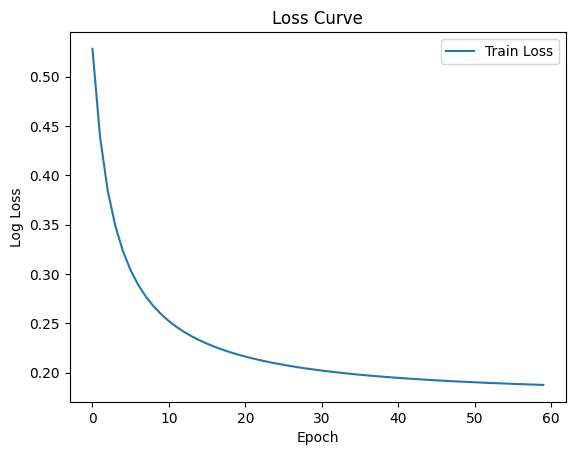

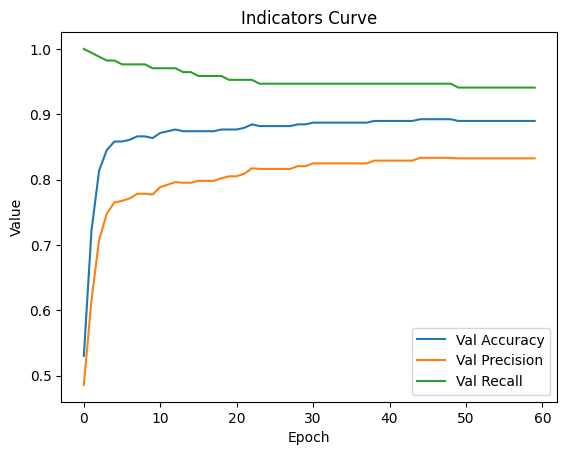

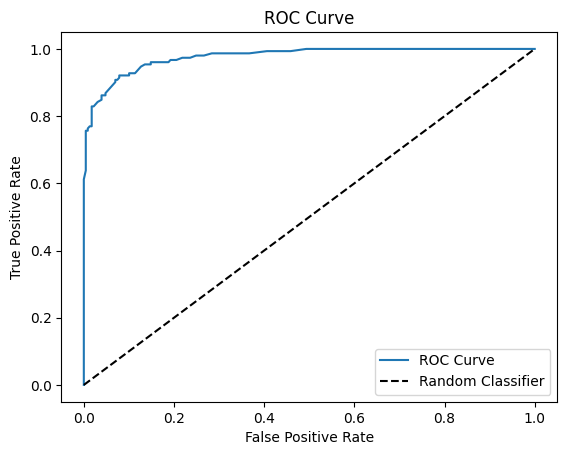

AUC: 0.9763


In [39]:
# 调用绘图函数
model.plot_loss()
model.plot_indicators()
model.plot_roc_curve(test_features.to_numpy(), test_labels)